# Trend maps (forcing fields)

**What's in this notebook**

- Loads gridded trend fields and ACCESS-CM2 trends.
- Plots trend maps.

_Cleaned copy of `trend_maps.ipynb`. Shared helpers in `functions.py`; outputs stripped — re-run to regenerate figures._


In [1]:
import sys, os

# make this repo's functions.py importable from any subfolder
_p = os.getcwd()
for _ in range(6):
    if os.path.exists(os.path.join(_p, 'functions.py')):
        sys.path.insert(0, _p); break
    _p = os.path.dirname(_p)
from functions import *  # shared helper functions


In [1]:
# Load variables produced by earlier (compute/loader) notebooks.
# Run those first; harmless if there's nothing saved yet.
# load_state(globals())


In [3]:
# Load Packages 

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import math
import cartopy.crs as ccrs
import calendar
from matplotlib.lines import Line2D
import os
import cartopy.feature as cfeature
import re
import seaborn as sns
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.stats import norm
# from mpl_toolkits.basemap import Basemap
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as patches
from scipy.stats import scoreatpercentile
# import xesmf as xe
from matplotlib.gridspec import GridSpec
import matplotlib

%matplotlib inline


In [4]:
era5_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/grid_cell_trend/perturb_gridcell_trend_era5.nc').sel(lat =slice(-20,20), lon = slice(110,300))*10*12
jra55_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/grid_cell_trend/perturb_gridcell_trend_jra55.nc').sel(lat =slice(-20,20), lon = slice(110,300))*10*12

In [5]:
noaa_sst = xr.open_dataset('/Users/isabelaconde/Desktop/data/conde2025/NOAA_sst.mon.mean.nc').sst.sel(time = slice('1982','2017')).sel(lat = slice(-80,80))
noaa_sst

def find_trend_values(dt):

    #Input: xarray array with time, lat, lon coordinates and a variable to calculate the trend
    #Output: xarray array with the trend values for each grid point
    dt = dt.sel(time=slice('1982','2017'))
    time, lat, lon = dt['time'].values, dt['lat'].values, dt['lon'].values
    sst_reshaped = dt.values.reshape(len(time), -1)
    degree = 1

    gradient_values = np.empty_like(sst_reshaped[0])
    for i in range(len(sst_reshaped[0])):
        y = sst_reshaped[:, i]
        coefficients = np.polyfit(np.arange(len(time)), y, degree)
        gradient_values[i] = coefficients[-2]

    gradient_values = gradient_values.reshape(lat.shape[0], lon.shape[0])
    gradient_da = xr.DataArray(gradient_values, coords={'lat': lat, 'lon': lon}, dims=['lat', 'lon'])
    return gradient_da 

noaa_trend = find_trend_values(noaa_sst.sel(lat =slice(-20,20), lon = slice(110,300)))*10*12
# noaa_trend

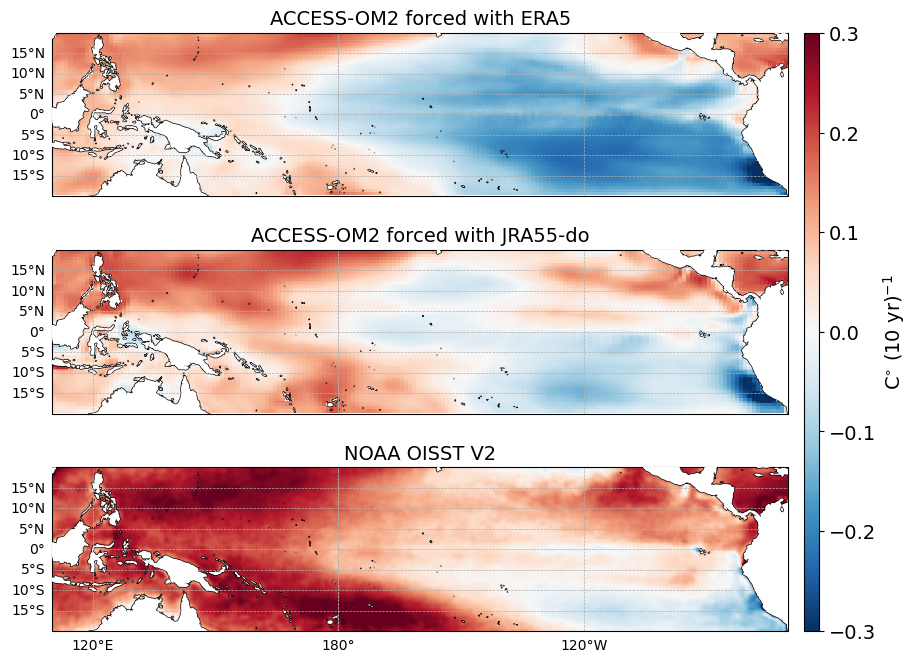

In [8]:

fig, axes = plt.subplots(
    3, 1,
    figsize=(10, 8),
    subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)}
)

v = 0.3

plots = [
    (era5_trend,  -v, v, "RdBu_r", "ACCESS-OM2 forced with ERA5"),
    (jra55_trend, -v, v, "RdBu_r", "ACCESS-OM2 forced with JRA55-do"),
    (noaa_trend,  -v, v, "RdBu_r", "NOAA OISST V2")
]

for i, (ax, (da, vmin, vmax, cmap, title)) in enumerate(zip(axes, plots)):

    da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        vmin=vmin,
        vmax=vmax,
        cmap=cmap,
        add_colorbar=False
    )

    ax.set_extent([110, 290, -20, 20], crs=ccrs.PlateCarree())

    ax.add_feature(cfeature.LAND, facecolor="white", zorder=10)
    ax.coastlines()

    ax.set_title(title, fontsize=14)

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        linestyle="--"
    )

    gl.top_labels = False
    gl.left_labels = True
    gl.right_labels = False

    # gl.xlabel_style = {"size": 14}
    # gl.ylabel_style = {"size": 14}

    if i == 2:
        gl.bottom_labels = True
    else:
        gl.bottom_labels = False

# single colourbar
cbar = fig.colorbar(
    axes[0].collections[0],
    ax=axes,
    orientation="vertical",
    fraction=0.03,
    pad=0.02,
    shrink=0.97,
    aspect=40
)

cbar.set_label(
    r"C$^{\circ}$ (10 yr)$^{-1}$",
    fontsize=14
)

cbar.ax.tick_params(labelsize=14)

plt.show()

In [ ]:
# Save this notebook's variables so later (plotting) notebooks can load them.
save_state(globals())
